In [ ]:
# Las siguientes son las importaciones necesarias basicas para trabajar un dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# importa el archivo de excel
df = pd.read_csv('/content/drive/MyDrive/parcialCienciaDeDatos/SOCR-HeightWeight.csv')

In [ ]:
# ¿Cuántas filas y columnas tiene el conjunto de datos?
df.shape
print(f'El conjunto de datos tiene {df.shape[0]} filas y {df.shape[1]} columnas')

#df.shape: Devuelve una tupla que representa las dimensiones del DataFrame. Primer elemento filas, segundo columnas.


El conjunto de datos tiene 25000 filas y 3 columnas


In [ ]:
# ¿Cuáles son los nombres de las columnas (variables)?
print(f'La primera columna del conjunto es "{df.columns[0]}", la segunda columna "{df.columns[1]}" y la tercera es "{df.columns[2]}"')

#df.columnas nos deuelve una lista de los nombre de las columnas del dataFrame y con el [numero] accedemos a cada uno de los elementos de esta lista pra mostrar el nombre de cada columna.

La primera columna del conjunto es "Index", la segunda columna "Height(Inches)" y la tercera es "Weight(Pounds)"


In [ ]:
# ¿Cuántas columnas numéricas y cuántas categóricas hay en el conjunto de datos?
print(f'Hay {df.dtypes.value_counts().iloc[0]} columnas numéricas y {df.dtypes.value_counts().iloc[1]} columnas categóricas')

#Con .dtypes accedemos a una serie con los tipos de datos de cada columna del dataframe, con el value_counts contamos la frecuencia de cada tipo de dato en la seriem en el elemento 0 tenemos las numericas y el ele

Hay 2 columnas numéricas y 1 columnas categóricas


In [ ]:
# ¿Cuántos valores nulos (NaN) hay en el conjunto de datos?
print(f'Hay {df.isnull().sum().sum()} valores nulos en el conjunto de datos')

Hay 0 valores nulos en el conjunto de datos


In [ ]:
#  Elimine la columna ‘Index’ del conjunto de datos
df.drop('Index', axis=1, inplace=True)
df.head()

#.drop es la funcion de pandas para #.drop es la funcion de pandas para eliminar filas o columnas , primer elemento es el nombre de la columna, con axis = 1 especificamos que es par auna columna (0 para filas), inplace=true modifica el dataframe sin necesidad de asignarle una nueva variable

,Height(Inches),Weight(Pounds)
0,65.78331,112.9925
1,71.51521,136.4873
2,69.39874,153.0269
3,68.21660,142.3354
4,67.78781,144.2971


In [ ]:
# ¿Cuál es el promedio y desviación estándar de las columnas numéricas del conjunto de datos?
print("El promedio de las columnas numéricas es:")
# Imprime un mensaje indicando que se mostrará el promedio de las columnas numéricas.

print(f'Height(Inches): {df.mean().iloc[0]}')
# Calcula e imprime el promedio de la columna 'Height(Inches)' usando la primera posición de 'mean()'.

print(f'Weight(Pounds): {df.mean().iloc[1]}')
# Calcula e imprime el promedio de la columna 'Weight(Pounds)' usando la segunda posición de 'mean()'.

print("")
# Imprime una línea en blanco para separar la salida.

print("La desviación estándar de las columnas numéricas es:")
# Imprime un mensaje indicando que se mostrará la desviación estándar de las columnas numéricas.

print(f'Height(Inches): {df.std().iloc[0]}')
# Calcula e imprime la desviación estándar de la columna 'Height(Inches)' usando la primera posición de 'std()'.

print(f'Weight(Pounds): {df.std().iloc[1]}')
# Calcula e imprime la desviación estándar de la columna 'Weight(Pounds)' usando la segunda posición de 'std()'.

El promedio de las columnas numéricas es:
Height(Inches): 67.99311359679999
Weight(Pounds): 127.07942116080001

La desviación estándar de las columnas numéricas es:
Height(Inches): 1.9016787712056105
Weight(Pounds): 11.660897563604278


In [ ]:
# ¿Cuál es la mediana y moda de las columnas numéricas del conjunto de datos?
moda_height = df['Height(Inches)'].mode()[0]
moda_weight = df['Weight(Pounds)'].mode()[0]
print("")
print("La mediana de las columnas numéricas es:")
print(f'Height(Inches): {df.median().iloc[0]}')
print(f'Weight(Pounds): {df.median().iloc[1]}')
print("")
print("La moda de las columnas numéricas es:")
print(f'Height(Inches): {moda_height}')
print(f'Weight(Pounds): {moda_weight}')


La mediana de las columnas numéricas es:
Height(Inches): 67.9957
Weight(Pounds): 127.15775

La moda de las columnas numéricas es:
Height(Inches): 65.65796
Weight(Pounds): 124.7975


In [ ]:
#  ¿Cuántos datos únicos hay en cada columna? (sugerencia: nunique())
print("Los datos únicos de las columnas son:")
print(f'Height(Inches): {df["Height(Inches)"].nunique()}')
print(f'Weight(Pounds): {df["Weight(Pounds)"].nunique()}')

Los datos únicos de las columnas son:
Height(Inches): 24503
Weight(Pounds): 24248


In [ ]:
# Ordena los datos de forma ascendente según la columna Height.
df.sort_values(by='Height(Inches)', inplace=True)
df.head(10)

,Height(Inches),Weight(Pounds)
13971,60.27836,110.11380
2651,60.61265,88.04646
20608,60.80620,113.91450
5641,60.86340,106.19390
12031,60.86977,108.86330
9876,61.30021,120.88190
6941,61.40550,119.26520
22507,61.57720,96.81420
6481,61.59011,99.81074
19198,61.82700,100.93910


In [ ]:
# Calcula el rango de las variables numéricas.
print("El rango de las variables numéricas es:")
print(f'Height(Inches): {df["Height(Inches)"].max() - df["Height(Inches)"].min()}')

El rango de las variables numéricas es:
Height(Inches): 14.87444


In [ ]:
# Crear una nueva columna llamada 'IMC_CLASS' que clasifique los datos según altura y peso en las siguientes categorías: Bajo peso, Normal, Sobrepeso y Obesidad.
imc = df['Weight(Pounds)'] / (df['Height(Inches)'] * df['Height(Inches)']) * 703
df['IMC_CLASS'] = pd.cut(imc, bins=[0, 18.5, 24.9, 29.9, float('inf')], labels=['Bajo peso', 'Normal', 'Sobrepeso', 'Obesidad'])
df.head()

,Height(Inches),Weight(Pounds),IMC_CLASS
13971,60.27836,110.11380,Normal
2651,60.61265,88.04646,Bajo peso
20608,60.80620,113.91450,Normal
5641,60.86340,106.19390,Normal
12031,60.86977,108.86330,Normal


In [ ]:
# Calcular el primer cuartil (Q1) y el tercer cuartil (Q3) de la columna Height(Inches)
Q1_height = df['Height(Inches)'].quantile(0.25)
Q3_height = df['Height(Inches)'].quantile(0.75)

# Imprimir los valores de Q1 y Q3
print(f'Primer cuartil (Q1) de Height(Inches): {Q1_height}')
print(f'Tercer cuartil (Q3) de Height(Inches): {Q3_height}')


Primer cuartil (Q1) de Height(Inches): 66.7043975
Tercer cuartil (Q3) de Height(Inches): 69.2729575


In [ ]:
# Crear dos nuevas columnas llamadas Outliers_Height y Outliers_Weight:
df['Outliers_Height'] = 0
df['Outliers_Weight'] = 0
df

,Height(Inches),Weight(Pounds),IMC_CLASS,Outliers_Height,Outliers_Weight
13971,60.27836,110.11380,Normal,0,0
2651,60.61265,88.04646,Bajo peso,0,0
20608,60.80620,113.91450,Normal,0,0
5641,60.86340,106.19390,Normal,0,0
12031,60.86977,108.86330,Normal,0,0
...,...,...,...,...,...
15209,74.59993,147.03720,Normal,0,0
13681,74.74047,155.54620,Normal,0,0
16752,74.84890,122.16640,Bajo peso,0,0
2481,75.11519,153.95620,Normal,0,0


In [ ]:
# • Outliers_Height se debe calcular usando el método de valores estandarizados sobre la columna Height.
df['Outliers_Height'] = (df['Height(Inches)'] - df['Height(Inches)'].mean()) / df['Height(Inches)'].std()
df

,Height(Inches),Weight(Pounds),IMC_CLASS,Outliers_Height,Outliers_Weight
13971,60.27836,110.11380,Normal,-4.056812,0
2651,60.61265,88.04646,Bajo peso,-3.881025,0
20608,60.80620,113.91450,Normal,-3.779247,0
5641,60.86340,106.19390,Normal,-3.749168,0
12031,60.86977,108.86330,Normal,-3.745819,0
...,...,...,...,...,...
15209,74.59993,147.03720,Normal,3.474202,0
13681,74.74047,155.54620,Normal,3.548105,0
16752,74.84890,122.16640,Bajo peso,3.605123,0
2481,75.11519,153.95620,Normal,3.745152,0


In [ ]:
# Calcular Q1, Q3 y el IQR para Weight(Pounds)
Q1_weight = df['Weight(Pounds)'].quantile(0.25)
Q3_weight = df['Weight(Pounds)'].quantile(0.75)
IQR_weight = Q3_weight - Q1_weight

# Calcular los límites inferior y superior para outliers
lower_limit = Q1_weight - 1.5 * IQR_weight
upper_limit = Q3_weight + 1.5 * IQR_weight

# Identificar outliers en Weight(Pounds) usando los límites calculados (marcar como 1 si es un outlier)
df['Outliers_Weight'] = df['Weight(Pounds)'].apply(lambda x: 1 if x < lower_limit or x > upper_limit else 0)

# Mostrar las primeras filas para verificar los resultados
df.head()

,Height(Inches),Weight(Pounds),IMC_CLASS,Outliers_Height,Outliers_Weight
13971,60.27836,110.11380,Normal,-4.056812,0
2651,60.61265,88.04646,Bajo peso,-3.881025,1
20608,60.80620,113.91450,Normal,-3.779247,0
5641,60.86340,106.19390,Normal,-3.749168,0
12031,60.86977,108.86330,Normal,-3.745819,0


In [ ]:
#  Agrupar el conjunto de datos por la columna IMC y usar el método de agregación conteo.
df_grouped = df.groupby('IMC_CLASS').count()
df_grouped

<ipython-input-102-453129fb6988>:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df.groupby('IMC_CLASS').count()


,Height(Inches),Weight(Pounds),Outliers_Height,Outliers_Weight
IMC_CLASS,,,,
Bajo peso,7453,7453,7453,7453
Normal,17541,17541,17541,17541
Sobrepeso,6,6,6,6
Obesidad,0,0,0,0


In [ ]:
# ¿Qué porcentaje de personas tiene un peso normal?
peso_normal = df[df['IMC_CLASS'] == 'Normal'].shape[0]
print(f'porcentaje de peso normal es de {(peso_normal / df.shape[0]) * 100}%')

porcentaje de peso normal es de 70.164%


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.10/dist-packages/matplotlib/pyplot.py'>

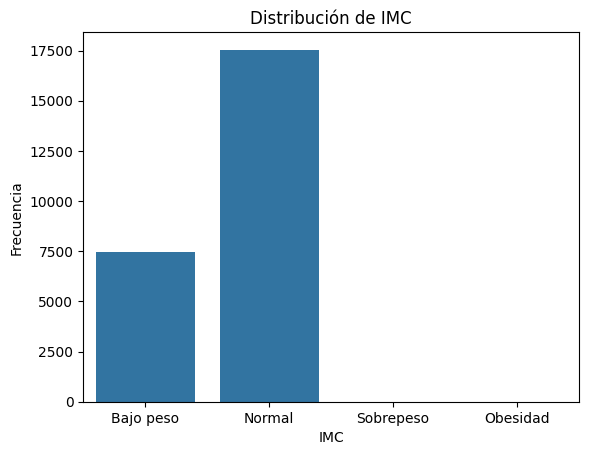

In [ ]:
# Crear un gráfico de barras para visualizar la agrupación realizada en el paso anterior (utilizar Seaborn, incluir etiquetas de título para los ejes y un título para el gráfico).

sns.countplot(x='IMC_CLASS', data=df)
plt.title('Distribución de IMC')
plt.xlabel('IMC')
plt.ylabel('Frecuencia')
plt

Text(0, 0.5, 'Frecuencia')

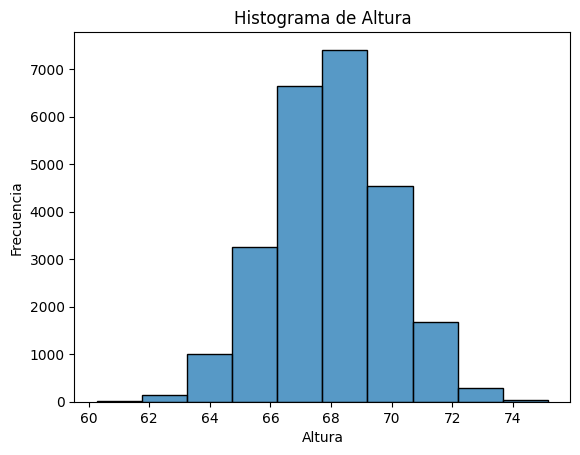

In [ ]:
# Crear un histograma para cada columna numérica del conjunto de datos (utilizar Seaborn, incluir etiquetas de título para los ejes y un título para el gráfico).
sns.histplot(data=df, x='Height(Inches)', bins=10)
plt.title('Histograma de Altura')
plt.xlabel('Altura')
plt.ylabel('Frecuencia')

Text(0.5, 0, 'Altura')

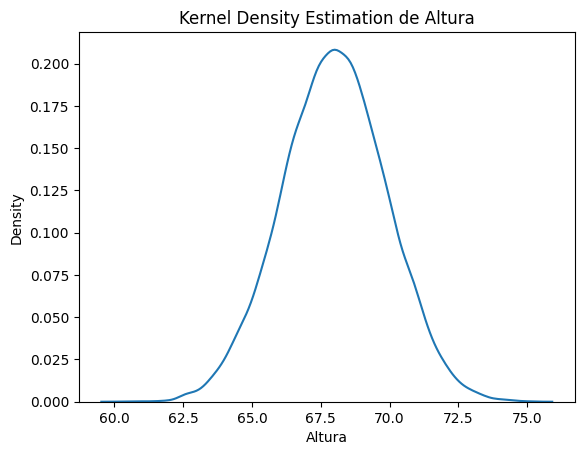

In [ ]:
# Crear un gráfico KDE para cada columna numérica del conjunto de datos. (utilizar Seaborn, incluir etiquetas de título para los ejes y un título para el gráfico)
sns.kdeplot(data=df, x='Height(Inches)')
plt.title('Kernel Density Estimation de Altura')
plt.xlabel('Altura')

In [ ]:
# Agrupar el conjunto de datos por la columna ‘Outliers_Height’ y usar los métodos de agregación conteo, media y desviación estándar (el método de agregación se aplica sobre la columna Height)
df_grouped = df.groupby('Outliers_Height').agg({'Height(Inches)': ['count', 'mean', 'std']})
df_grouped

Height(Inches)              
                         count      mean std
Outliers_Height                             
-4.056812                    1  60.27836 NaN
-3.881025                    1  60.61265 NaN
-3.779247                    1  60.80620 NaN
-3.749168                    1  60.86340 NaN
-3.745819                    1  60.86977 NaN
...                        ...       ...  ..
 3.474202                    1  74.59993 NaN
 3.548105                    1  74.74047 NaN
 3.605123                    1  74.84890 NaN
 3.745152                    1  75.11519 NaN
 3.764929                    1  75.15280 NaN

[24503 rows x 3 columns]

In [ ]:
# . Agrupe el conjunto de datos por la columna ‘Outliers_Weight’ y usa los métodos de agregación conteo, media y desviación estándar (el método de agregación se aplica sobre la columna Weight)
df_grouped = df.groupby('Outliers_Weight').agg({'Weight(Pounds)': ['count', 'mean', 'std']})
df_grouped

Weight(Pounds)                       
                         count        mean        std
Outliers_Weight                                      
0                        24809  127.110369  11.292403
1                          191  123.059614  34.995602

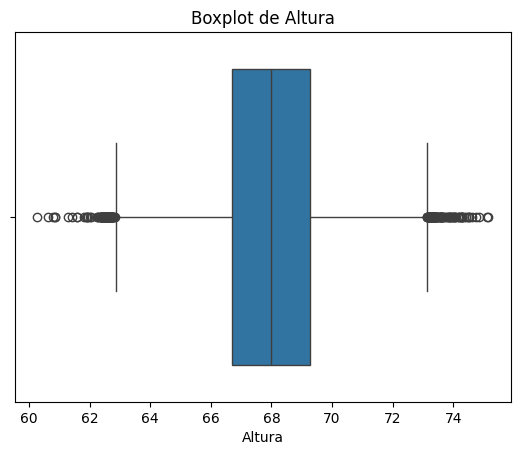

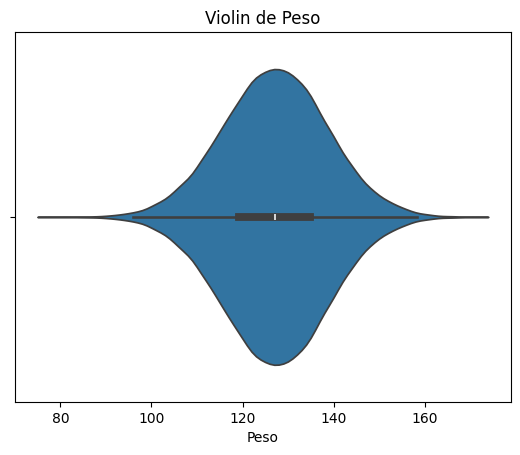

In [ ]:
#  Crear un boxplot para la variable Height y un gráfico de violín para la variable Weight
sns.boxplot(x=df['Height(Inches)'])
plt.title('Boxplot de Altura')
plt.xlabel('Altura')
plt.show()

sns.violinplot(x=df['Weight(Pounds)'])
plt.title('Violin de Peso')
plt.xlabel('Peso')
plt.show()

In [ ]:
# ¿Cuántos datos atípicos tiene cada variable?
print(f'Hay {df[df["Outliers_Height"] == 1].shape[0]} datos atípicos en Height')
print(f'Hay {df[df["Outliers_Weight"] == 1].shape[0]} datos atípicos en Weight')

Hay 0 datos atípicos en Height
Hay 191 datos atípicos en Weight


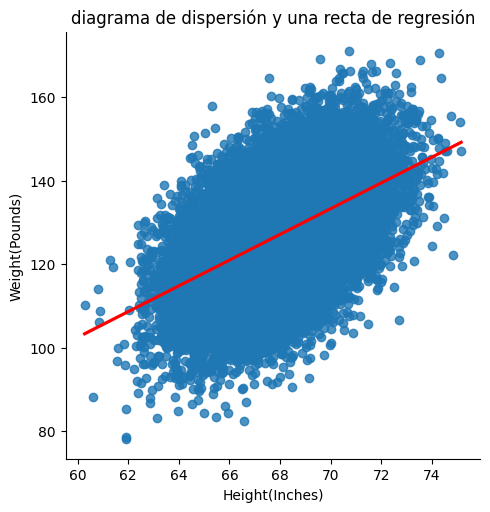

In [ ]:
#Crear un gráfico combinado de diagrama de dispersión y una recta de regresión para las variables numéricas Height y Weight
sns.lmplot(x='Height(Inches)', y='Weight(Pounds)', data=df, line_kws={'color': 'red'})
plt.title('diagrama de dispersión y una recta de regresión')
plt.show()